# California Home Price Prediction
## Week 7: Gradient Boosting

This notebook tests XGBoost against the Week 6 Random Forest. It uses the same features, time split, and preprocessing so the comparison is fair.

In [1]:
from pathlib import Path
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from xgboost import XGBRegressor

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

RANDOM_STATE = 42
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = PROJECT_ROOT / "data" / "raw" / "California"

## 1. Load and clean the data

Use the same 15 months, property filters, duplicate rule, and target-quality checks as the earlier notebooks. `ListPrice` is used only to remove obvious target-entry errors and is never a model feature.

In [2]:
numeric_features = [
    "LivingArea", "BedroomsTotal", "BathroomsTotalInteger",
    "LotSizeSquareFeet", "YearBuilt", "Latitude", "Longitude",
    "GarageSpaces", "ParkingTotal",
]
categorical_features = [
    "City", "CountyOrParish", "PostalCode", "PoolPrivateYN",
    "ViewYN", "NewConstructionYN", "AttachedGarageYN",
]
features = numeric_features + categorical_features
target = "ClosePrice"

columns = [
    "ListingKey", "CloseDate", target, "ListPrice",
    "PropertyType", "PropertySubType", *features,
]

frames = []
for path in sorted(RAW_DIR.glob("CRMLSSold*.csv")):
    month = int(path.stem[-6:])
    frame = pd.read_csv(path, usecols=lambda column: column in columns, low_memory=False)
    frame["SourceMonth"] = month
    frames.append(frame)

df = pd.concat(frames, ignore_index=True)
df = df[
    df["PropertyType"].eq("Residential")
    & df["PropertySubType"].eq("SingleFamilyResidence")
].copy()
df["CloseDate"] = pd.to_datetime(df["CloseDate"], errors="coerce")

for column in [target, "ListPrice", *numeric_features]:
    df[column] = pd.to_numeric(df[column], errors="coerce")
for column in categorical_features:
    df[column] = df[column].map(lambda value: str(value) if pd.notna(value) else np.nan)

df = df.sort_values(["SourceMonth", "CloseDate"]).drop_duplicates("ListingKey", keep="last")
price_ratio = df[target] / df["ListPrice"]
valid_target = (
    df[target].ge(10_000)
    & (df["ListPrice"].le(0) | df["ListPrice"].isna() | price_ratio.between(0.2, 5.0))
)
df = df[valid_target].copy()

invalid_rules = {
    "LivingArea": df["LivingArea"] <= 0,
    "BedroomsTotal": df["BedroomsTotal"] < 0,
    "BathroomsTotalInteger": df["BathroomsTotalInteger"] < 0,
    "LotSizeSquareFeet": df["LotSizeSquareFeet"] <= 0,
    "YearBuilt": (df["YearBuilt"] < 1800) | (df["YearBuilt"] > df["CloseDate"].dt.year),
    "Latitude": ~df["Latitude"].between(32, 42),
    "Longitude": ~df["Longitude"].between(-125, -114),
    "GarageSpaces": df["GarageSpaces"] < 0,
    "ParkingTotal": df["ParkingTotal"] < 0,
}
for column, invalid in invalid_rules.items():
    df.loc[invalid.fillna(False), column] = np.nan

print(f"Files loaded: {len(frames)}")
print(f"Usable single-family sales: {len(df):,}")
print(f"Period: {df['SourceMonth'].min()} to {df['SourceMonth'].max()}")

Files loaded: 15
Usable single-family sales: 161,082
Period: 202502 to 202604


## 2. Keep the chronological evaluation design

- **Development:** April 2025 to February 2026
- **Validation:** March 2026, used for light tuning
- **Final training:** April 2025 to March 2026
- **Test:** April 2026, used once for the final comparison

This preserves the real forecasting order and prevents future information from entering training.

In [3]:
development = df[df["SourceMonth"].between(202504, 202602)].copy()
validation = df[df["SourceMonth"] == 202603].copy()
train = df[df["SourceMonth"].between(202504, 202603)].copy()
test = df[df["SourceMonth"] == 202604].copy()

split_summary = pd.DataFrame({
    "period": ["Apr 2025–Feb 2026", "Mar 2026", "Apr 2025–Mar 2026", "Apr 2026"],
    "purpose": ["Development", "Validation", "Final training", "Final test"],
    "rows": [len(development), len(validation), len(train), len(test)],
})
display(split_summary)

,period,purpose,rows
0,Apr 2025–Feb 2026,Development,118454
1,Mar 2026,Validation,11165
2,Apr 2025–Mar 2026,Final training,129619
3,Apr 2026,Final test,12024


## 3. Build one shared preprocessing pipeline

Numeric values use median imputation with missing indicators. Categorical values use an `Unknown` label and one-hot encoding, with rare levels grouped. The transformer is fitted only on the relevant training period. Tree models do not need scaling.

In [4]:
def make_preprocessor():
    return ColumnTransformer([
        ("numeric", SimpleImputer(strategy="median", add_indicator=True), numeric_features),
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
            ("onehot", OneHotEncoder(
                handle_unknown="infrequent_if_exist",
                min_frequency=10,
                sparse_output=True,
            )),
        ]), categorical_features),
    ])


development_preprocessor = make_preprocessor()
X_development = development_preprocessor.fit_transform(development[features])
X_validation = development_preprocessor.transform(validation[features])
y_development = development[target]
y_validation = validation[target]

print(f"Encoded development shape: {X_development.shape}")

Encoded development shape: (118454, 1631)


## 4. Light XGBoost tuning

Test only six practical combinations of tree depth, learning rate, and number of trees. March validation R² selects the final setting; April remains untouched.

In [5]:
candidates = [
    {"max_depth": 4, "learning_rate": 0.05, "n_estimators": 400},
    {"max_depth": 6, "learning_rate": 0.05, "n_estimators": 400},
    {"max_depth": 8, "learning_rate": 0.05, "n_estimators": 400},
    {"max_depth": 4, "learning_rate": 0.10, "n_estimators": 250},
    {"max_depth": 6, "learning_rate": 0.10, "n_estimators": 250},
    {"max_depth": 8, "learning_rate": 0.10, "n_estimators": 250},
]

tuning_rows = []
for settings in candidates:
    model = XGBRegressor(
        **settings,
        objective="reg:squarederror",
        tree_method="hist",
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    start = time.perf_counter()
    model.fit(X_development, y_development)
    predicted = model.predict(X_validation)
    tuning_rows.append({
        **settings,
        "validation_r2": r2_score(y_validation, predicted),
        "validation_mae": mean_absolute_error(y_validation, predicted),
        "fit_seconds": time.perf_counter() - start,
    })

tuning_results = pd.DataFrame(tuning_rows).sort_values(
    ["validation_r2", "validation_mae"], ascending=[False, True]
).reset_index(drop=True)
display(tuning_results.style.format({
    "learning_rate": "{:.2f}", "validation_r2": "{:.3f}",
    "validation_mae": "${:,.0f}", "fit_seconds": "{:.1f}",
}))

,max_depth,learning_rate,n_estimators,validation_r2,validation_mae,fit_seconds
0,8,0.10,250,0.832,"$215,308",1.5
1,8,0.05,400,0.832,"$220,861",2.3
2,6,0.05,400,0.830,"$241,994",1.7
3,6,0.10,250,0.828,"$235,752",1.1
4,4,0.05,400,0.780,"$283,213",1.4
5,4,0.10,250,0.769,"$272,559",0.8


## 5. Refit and compare on April 2026

Refit the selected XGBoost model on all 12 training months. Compare it with the already evaluated Week 6 Random Forest benchmark, which used the same rows, features, and preprocessing.

In [6]:
best_settings = {
    key: (int(tuning_results.loc[0, key]) if key != "learning_rate" else float(tuning_results.loc[0, key]))
    for key in ["max_depth", "learning_rate", "n_estimators"]
}

xgb_model = XGBRegressor(
    **best_settings,
    objective="reg:squarederror", tree_method="hist",
    subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
    random_state=RANDOM_STATE, n_jobs=-1,
)

final_preprocessor = make_preprocessor()
X_train = final_preprocessor.fit_transform(train[features])
X_test = final_preprocessor.transform(test[features])
y_train = train[target]
y_test = test[target]

start = time.perf_counter()
xgb_model.fit(X_train, y_train)
xgb_predictions = xgb_model.predict(X_test)
xgb_seconds = time.perf_counter() - start

results_rows = [
    {
        "model": "Week 6 Random Forest",
        "test_r2": 0.767,
        "test_mae": 204350,
        "test_rmse": 762596,
        "fit_seconds": np.nan,
    },
    {
        "model": "Week 7 XGBoost",
        "test_r2": r2_score(y_test, xgb_predictions),
        "test_mae": mean_absolute_error(y_test, xgb_predictions),
        "test_rmse": mean_squared_error(y_test, xgb_predictions) ** 0.5,
        "fit_seconds": xgb_seconds,
    },
]

results = pd.DataFrame(results_rows).sort_values("test_r2", ascending=False).reset_index(drop=True)
display(results.style.format({
    "test_r2": "{:.3f}", "test_mae": "${:,.0f}",
    "test_rmse": "${:,.0f}", "fit_seconds": "{:.1f}",
}))
print("Selected XGBoost settings:", best_settings)

,model,test_r2,test_mae,test_rmse,fit_seconds
0,Week 6 Random Forest,0.767,"$204,350","$762,596",nan
1,Week 7 XGBoost,0.745,"$237,426","$796,469",1.6


Selected XGBoost settings: {'max_depth': 8, 'learning_rate': 0.1, 'n_estimators': 250}


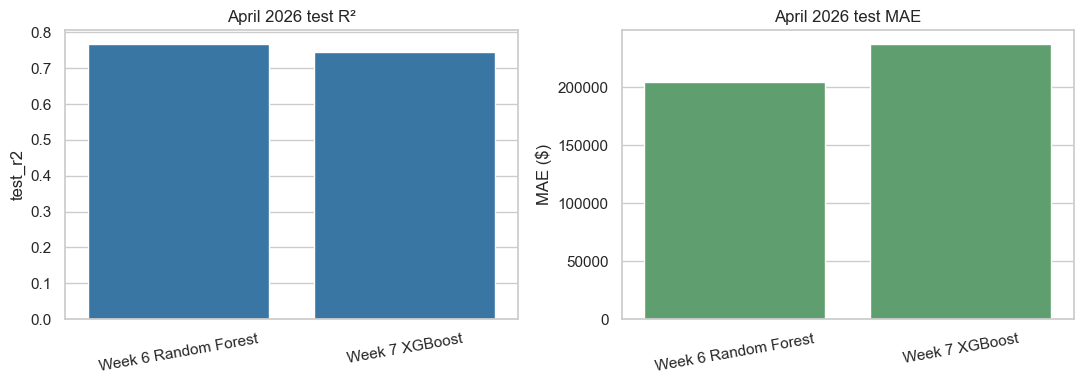

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(data=results, x="model", y="test_r2", color="#2878B5", ax=axes[0])
axes[0].set_title("April 2026 test R²")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=10)
sns.barplot(data=results, x="model", y="test_mae", color="#55A868", ax=axes[1])
axes[1].set_title("April 2026 test MAE")
axes[1].set_xlabel("")
axes[1].set_ylabel("MAE ($)")
axes[1].tick_params(axis="x", rotation=10)
plt.tight_layout()
plt.show()

## 6. Review the Week 7 model

The scatter plot shows a readable sample below the 99th percentile. All test rows, including expensive properties, remain included in the reported metrics.

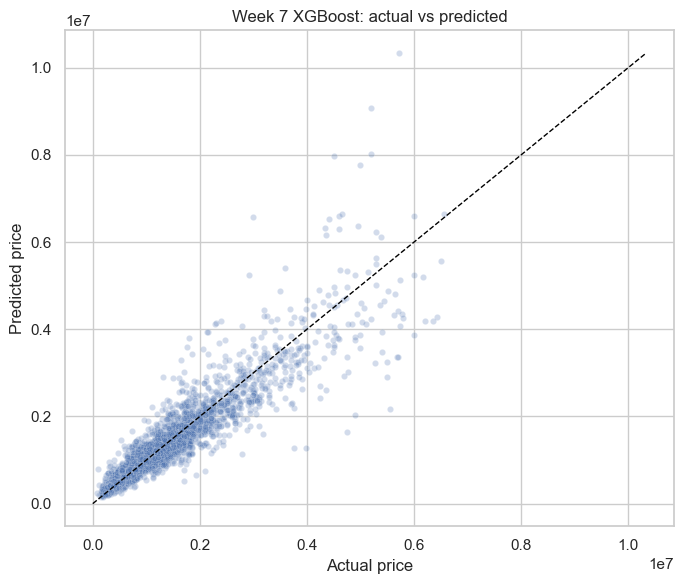

In [8]:
plot_data = pd.DataFrame({
    "Actual price": y_test.to_numpy(),
    "Predicted price": xgb_predictions,
})
plot_data = plot_data[plot_data["Actual price"] <= y_test.quantile(0.99)]
plot_data = plot_data.sample(min(4000, len(plot_data)), random_state=RANDOM_STATE)

plt.figure(figsize=(7, 6))
sns.scatterplot(data=plot_data, x="Actual price", y="Predicted price", alpha=0.25, s=20)
line_max = plot_data[["Actual price", "Predicted price"]].to_numpy().max()
plt.plot([0, line_max], [0, line_max], "--", color="black", linewidth=1)
plt.title("Week 7 XGBoost: actual vs predicted")
plt.tight_layout()
plt.show()

,feature,importance
3,City,0.395
13,PostalCode,0.354
4,CountyOrParish,0.161
7,LivingArea,0.023
12,PoolPrivateYN,0.017
1,BathroomsTotalInteger,0.015
5,GarageSpaces,0.010
8,Longitude,0.005
6,Latitude,0.005
15,YearBuilt,0.003


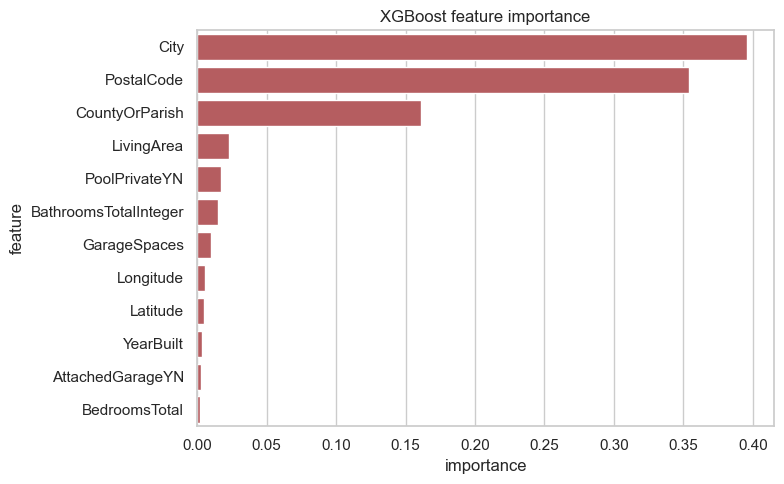

In [9]:
encoded_names = final_preprocessor.get_feature_names_out()
encoded_importance = pd.DataFrame({
    "encoded_feature": encoded_names,
    "importance": xgb_model.feature_importances_,
})

def original_feature(encoded_name):
    for feature in features:
        if feature in encoded_name:
            return feature
    return encoded_name

feature_importance = (
    encoded_importance.assign(feature=encoded_importance["encoded_feature"].map(original_feature))
    .groupby("feature", as_index=False)["importance"].sum()
    .sort_values("importance", ascending=False)
)
display(feature_importance.head(12).style.format({"importance": "{:.3f}"}))

plt.figure(figsize=(8, 5))
sns.barplot(data=feature_importance.head(12), x="importance", y="feature", color="#C44E52")
plt.title("XGBoost feature importance")
plt.tight_layout()
plt.show()

## Conclusion

- Tested XGBoost with six light hyperparameter combinations.
- Used March 2026 for model selection and kept April 2026 untouched for final testing.
- Compared XGBoost directly with the optimized Week 6 Random Forest under the same pipeline.
- Reported R², MAE, RMSE, training time, and the most influential features.

Week 8 will expand evaluation with MAPE, MdAPE, and performance by price band.